# Diagnóstico: ¿dónde cambió la proporción de `mora`?
Se esperaba ≈ 85 % no moroso / 15 % moroso, pero el EDA mostró 70.4 % de `mora = 1`.  
Este notebook revisa la proporción en **cada etapa** del flujo para ubicar dónde aparece la diferencia.

## 1. Proporción de `mora` en cada archivo

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# Ajusta los nombres si tus archivos se llaman distinto
ARCHIVOS = {
    "1. original (dataset.csv)": "data.csv",
    "2. reducido": "dataset_reducido.csv",
    "3. simulado": "dataset_simulado.csv",
    "4. limpio": "dataset_limpio.csv",
}

filas, datos = [], {}
for etapa, ruta in ARCHIVOS.items():
    if not os.path.exists(ruta):
        filas.append({"etapa": etapa, "archivo": ruta, "filas": None, "mora=0": None, "mora=1": None, "% mora=1": None})
        continue
    d = pd.read_csv(ruta)
    datos[etapa] = d
    vc = d["mora"].value_counts()
    filas.append({"etapa": etapa, "archivo": ruta, "filas": len(d),
                  "mora=0": vc.get(0, 0), "mora=1": vc.get(1, 0),
                  "% mora=1": round(d["mora"].mean() * 100, 2)})

for nombre in ["y_train.csv", "y_test.csv"]:
    if os.path.exists(nombre):
        y = pd.read_csv(nombre).squeeze("columns")
        filas.append({"etapa": nombre, "archivo": nombre, "filas": len(y),
                      "mora=0": int((y == 0).sum()), "mora=1": int((y == 1).sum()),
                      "% mora=1": round(y.mean() * 100, 2)})

pd.DataFrame(filas)

,etapa,archivo,filas,mora=0,mora=1,% mora=1
0,1. original (dataset.csv),data.csv,8399,2484,5915,70.43
1,2. reducido,dataset_reducido.csv,8399,2484,5915,70.43
2,3. simulado,dataset_simulado.csv,8399,2484,5915,70.43
3,4. limpio,dataset_limpio.csv,8399,2484,5915,70.43
4,y_train.csv,y_train.csv,6719,1987,4732,70.43
5,y_test.csv,y_test.csv,1680,497,1183,70.42


## 2. Valores distintos de `mora` en el original (¿hay otros códigos?)

In [12]:
orig = datos.get("1. original (dataset.csv)")
if orig is not None:
    print(orig["mora"].value_counts(dropna=False))
else:
    print("No se encontró dataset.csv en esta carpeta.")

mora
1    5915
0    2484
Name: count, dtype: int64


## 3. ¿El valor de `mora` cambió entre etapas?

In [13]:
etapas = list(datos.keys())
for a, b in zip(etapas[:-1], etapas[1:]):
    da, db = datos[a], datos[b]
    if len(da) == len(db):
        iguales = (da["mora"].values == db["mora"].values).all()
        print(f"{a}  ->  {b}: misma cantidad de filas; mora idéntica fila a fila = {iguales}")
    else:
        print(f"{a}  ->  {b}: distinta cantidad de filas ({len(da)} vs {len(db)})")

1. original (dataset.csv)  ->  2. reducido: misma cantidad de filas; mora idéntica fila a fila = True
2. reducido  ->  3. simulado: misma cantidad de filas; mora idéntica fila a fila = True
3. simulado  ->  4. limpio: misma cantidad de filas; mora idéntica fila a fila = True


## 4. ¿Está ordenado el archivo?
En el EDA, las primeras 10 filas tenían `mora = 0`, algo muy poco probable en un dataset con 70 % de unos si estuviera mezclado.  
Se calcula la proporción de `mora = 1` por bloques de filas consecutivas.

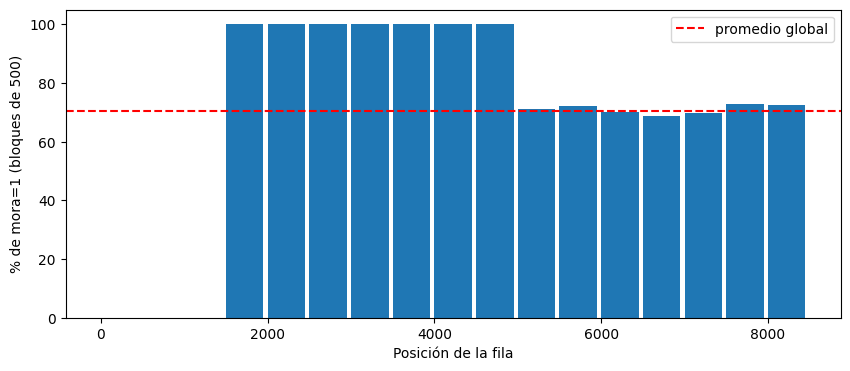

Primeras 20 filas de mora : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Últimas 20 filas de mora  : [1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0]


In [14]:
base = datos.get("3. simulado", datos.get("4. limpio"))
bloque = 500
prop = base["mora"].groupby(np.arange(len(base)) // bloque).mean() * 100

plt.figure(figsize=(10, 4))
plt.bar(prop.index * bloque, prop.values, width=bloque * 0.9, align="edge")
plt.axhline(base["mora"].mean() * 100, color="red", ls="--", label="promedio global")
plt.xlabel("Posición de la fila")
plt.ylabel(f"% de mora=1 (bloques de {bloque})")
plt.legend()
plt.show()

print("Primeras 20 filas de mora :", base["mora"].head(20).tolist())
print("Últimas 20 filas de mora  :", base["mora"].tail(20).tolist())

## 5. Relación de `mora` con `atraso` y `clasif_sbs` en el original (si existen)

In [15]:
if orig is not None:
    if "atraso" in orig:
        cortes = pd.cut(orig["atraso"], [-1, 0, 8, 30, 60, 9999], labels=["0", "1-8", "9-30", "31-60", ">60"])
        print("% de mora=1 según días de atraso (original):")
        print((orig.groupby(cortes, observed=True)["mora"].agg(n="count", pct_mora1=lambda s: s.mean() * 100)).round(2), "\n")
    if "clasif_sbs" in orig:
        print("% de mora=1 según clasif_sbs (original):")
        print((orig.groupby("clasif_sbs")["mora"].agg(n="count", pct_mora1=lambda s: s.mean() * 100)).round(2))

% de mora=1 según días de atraso (original):
           n  pct_mora1
atraso                 
0       5224      65.37
1-8     2028      76.78
9-30     942      82.27
31-60    172      81.40
>60       33      84.85 

% de mora=1 según clasif_sbs (original):
               n  pct_mora1
clasif_sbs                 
0           5282      67.34
1           2090      74.45
2            644      77.33
3            177      78.53
4            206      80.10


## Qué copiar y enviar
Las salidas de las secciones 1, 2, 3 y 4 (la tabla, los conteos y la figura). Con eso se ve en qué etapa cambia la proporción.